In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import sys
sys.path.append('..')
from pathlib import Path
from tqdm import trange
import csv
import scipy.io
import scipy.stats



In [2]:
with open('DG_EXP_NAMES.txt', 'r') as f:
    EXP_NAMES = [line.strip() for line in f if line.strip()]

In [3]:
gen_path='/bucket/ReiterU/electrophysiology/squidOL/'
DEBUG=True

In [4]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager

# Manually create a font property using the full path
arial_font = font_manager.FontProperties(fname='/bucket/ReiterU/common/fonts/arial.ttf')

# Set default font family to use this font
mpl.rcParams['font.family'] = arial_font.get_name()

# Set other style settings
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})
mpl.rcParams['font.family'] = arial_font.get_name()

In [5]:
def get_DSI_OSI(fir_matrix, set_ORI, set_SF):

    thetas = np.deg2rad(set_ORI)

    # Collapse across SF and/or TF if needed
    if len(set_SF) > 1:
        # Collapse across first axis (SF), then keep only the first 3 TFs
        ori_bars = np.sum(np.sum(fir_matrix[1:], axis=1)[:3], axis=0)
    else:
        ori_bars = np.sum(fir_matrix[1:], axis=0)

    # Normalize baseline
    ori_bars = ori_bars - np.nanmin(ori_bars)

    # Identify preferred, opposite, orthogonal orientations
    pref_ori_index = np.argmax(ori_bars)
    n_oris = len(set_ORI)

    opposite_ori_index = (pref_ori_index + n_oris // 2) % n_oris
    ortho_ori_index1 = (pref_ori_index + n_oris // 4) % n_oris
    ortho_ori_index2 = (pref_ori_index + 3 * n_oris // 4) % n_oris

    # Extract relevant responses
    R_pref = ori_bars[pref_ori_index]
    R_opposite = ori_bars[opposite_ori_index]
    R_ortho1 = ori_bars[ortho_ori_index1]
    R_ortho2 = ori_bars[ortho_ori_index2]

    # Handle division by zero safely
    DSI = (R_pref - R_opposite) / R_pref if R_pref != 0 else np.nan
    OSI = ((R_pref + R_opposite) - (R_ortho1 + R_ortho2)) / (R_pref + R_opposite) if (R_pref + R_opposite) != 0 else np.nan

    return ori_bars, DSI, OSI


def get_gDSI_gOSI(fir_matrix,set_ORI,set_SF):
    
    
    thetas = np.deg2rad(set_ORI)
    
    if len(set_SF)>1:
        ori_bars = np.sum(np.sum(fir_matrix[1:], axis=1)[:3], axis=0)
    else:
        ori_bars = np.sum(fir_matrix[1:], axis=0)
    ori_bars=ori_bars-np.nanmin(ori_bars)
    vec_sum = np.sum(ori_bars * np.exp(1j * thetas))
    gDSI = np.abs(vec_sum) / np.sum(ori_bars)
    pref_ori = np.angle(vec_sum, deg=True) % 360  # Preferred direction


    vec_sum_osi = np.sum(ori_bars * np.exp(1j * 2 * thetas))
    gOSI = np.abs(vec_sum_osi) / np.sum(ori_bars)
    pref_ori = (0.5 * np.angle(vec_sum_osi, deg=True)) % 180

    return ori_bars,gDSI,gOSI

def shuffle_responses(arr):
    shuf_arr=np.copy(arr)
    np.random.shuffle(shuf_arr)
    return shuf_arr

In [6]:
rec_paths=[]
for exp_name in EXP_NAMES:
    rec_list=os.listdir(gen_path+exp_name)
    found=False
    for i in rec_list:
        if i.endswith('DG_LUM'):
            rec_paths.append(gen_path+exp_name+'/'+i)
            found=True
            break
    if found==False:
        print('No matching recording in {}!!'.format(exp_name))

In [7]:
dataset_ids=[]
ALL_STIM_WINDOWS=[]
stims=[]
stim_names=[]
ALL_spikes=[]
ALL_ids=[]
ALL_channels=[]
for rec in range(len(rec_paths)):
    rec_path=rec_paths[rec]
    post_path=rec_path+'/post_processed/'
    for probe in os.listdir(post_path):
        if len(os.listdir(post_path+'/'+probe))!=0:
            stim_windows=np.load(rec_path+'/STIM_WINDOWS.npy')
            ALL_STIM_WINDOWS.append(stim_windows)
            sort_path=post_path+'/'+probe+'/'
            dataset_ids.append(EXP_NAMES[rec]+'_'+probe)
            stim_path=[rec_path+'/visual_stim/'+i for i in os.listdir(rec_path+'/visual_stim/') if 'csv' in i][0]
            stim_name=[i for i in os.listdir(rec_path+'/visual_stim/') if 'csv' in i][0]
            stim_names.append(stim_name)
            with open(stim_path, newline='') as f:
                g=csv.reader(f)
                params=[i for i in g]
            stims.append(params)
    
    
            spike_t_matrix=np.load(sort_path+'/spike_t_matrix.npy',allow_pickle=True)
            g_channels=np.load(sort_path+'/g_channels.npy')
            g_ids=np.load(sort_path+'/g_ids.npy')

            ALL_spikes.append(spike_t_matrix)
            ALL_ids.append(g_ids)
            ALL_channels.append(g_channels)


In [8]:
ALL_stim_unit_FRs = []

for dataset in trange(len(dataset_ids)):
    stim_windows = ALL_STIM_WINDOWS[dataset]
    g_ids = ALL_ids[dataset]
    spike_t_matrix = ALL_spikes[dataset]

    stim_unit_FRs = np.zeros((len(g_ids), len(stim_windows)))

    for unit in range(len(g_ids)):
        spike_times = spike_t_matrix[unit]
        if len(spike_times) == 0:
            continue

        starts = stim_windows[:, 0]
        ends = stim_windows[:, 1]

        indices = np.searchsorted(starts, spike_times, side='right') - 1
        valid = (indices >= 0) & (indices < len(stim_windows)) & (spike_times < ends[indices] + 0.03)
        np.add.at(stim_unit_FRs[unit], indices[valid], 1)

    ALL_stim_unit_FRs.append(stim_unit_FRs)


100%|███████████████████████████████████████████████████████████████| 27/27 [00:02<00:00,  9.33it/s]


In [9]:
N_shufs = 1000
ALL_SHUFF_GDSIS=[]
ALL_SHUFF_GOSIS=[]
for data_index in range(len(dataset_ids)):
    stim_unit_FRs = ALL_stim_unit_FRs[data_index]
    g_ids = ALL_ids[data_index]
    g_channels = ALL_channels[data_index]
    spike_t_matrix = ALL_spikes[data_index]
    params = stims[data_index]
    stim_windows = ALL_STIM_WINDOWS[data_index]

    params = params[:len(stim_windows) + 1]
    stim_SFs = np.asarray([i[0] for i in params[1:]], dtype=float)
    stim_TFs = np.asarray([i[1] for i in params[1:]], dtype=float)
    stim_ORIs = np.asarray([i[2] for i in params[1:]], dtype=float)

    set_SF = np.sort(np.unique(stim_SFs))
    set_TF = np.sort(np.unique(stim_TFs))
    set_ORI = np.sort(np.unique(stim_ORIs))

    DATASET_SHUFF_GDSIS=[]
    DATASET_SHUFF_GOSIS=[]

    for unit in trange(len(g_ids)):
        UNIT_SHUFF_GDSIS=[]
        UNIT_SHUFF_GOSIS=[]
        orig_X = stim_unit_FRs[unit]

        if len(set_SF) > 1:
            # ---------------------- 3D case: SF x TF x ORI ----------------------
            sf_indices = np.searchsorted(set_SF, stim_SFs)
            tf_indices = np.searchsorted(set_TF, stim_TFs)
            ori_indices = np.searchsorted(set_ORI, stim_ORIs)

            # Precompute count matrix
            count_matrix = np.zeros((len(set_SF), len(set_TF), len(set_ORI)))
            for i in range(len(stim_SFs)):
                count_matrix[sf_indices[i], tf_indices[i], ori_indices[i]] += 1
            count_matrix[count_matrix == 0] = 1

            # Generate shuffled responses
            shuf_X = np.array([shuffle_responses(orig_X) for _ in range(N_shufs)])  # (N_shufs, N_stim)
            reps = np.arange(N_shufs)[:, None]  # shape (N_shufs, 1)

            # Allocate final matrix
            shuf_resps = np.zeros((N_shufs, len(set_SF), len(set_TF), len(set_ORI)))

            # Fill using broadcasting
            shuf_resps[reps, sf_indices[None, :], tf_indices[None, :], ori_indices[None, :]] += shuf_X

            # Normalize
            shuf_resps /= count_matrix[None, :, :, :]

        else:
            # ---------------------- 2D case: TF x ORI ----------------------
            tf_indices = np.searchsorted(set_TF, stim_TFs)
            ori_indices = np.searchsorted(set_ORI, stim_ORIs)

            # Precompute count matrix
            count_matrix = np.zeros((len(set_TF), len(set_ORI)))
            for i in range(len(stim_TFs)):
                count_matrix[tf_indices[i], ori_indices[i]] += 1
            count_matrix[count_matrix == 0] = 1

            # Generate shuffled responses
            shuf_X = np.array([shuffle_responses(orig_X) for _ in range(N_shufs)])  # (N_shufs, N_stim)
            reps = np.arange(N_shufs)[:, None]  # shape (N_shufs, 1)

            # Allocate final matrix
            shuf_resps = np.zeros((N_shufs, len(set_TF), len(set_ORI)))

            # Fill using broadcasting
            shuf_resps[reps, tf_indices[None, :], ori_indices[None, :]] += shuf_X

            # Normalize
            shuf_resps /= count_matrix[None, :, :]
            
        for n in range(N_shufs):
            _,gDSI,gOSI=get_gDSI_gOSI(shuf_resps[n],set_ORI,set_SF)
            UNIT_SHUFF_GDSIS.append(gDSI)
            UNIT_SHUFF_GOSIS.append(gOSI)
        DATASET_SHUFF_GDSIS.append(UNIT_SHUFF_GDSIS)
        DATASET_SHUFF_GOSIS.append(UNIT_SHUFF_GOSIS)
    ALL_SHUFF_GDSIS.append(DATASET_SHUFF_GDSIS)
    ALL_SHUFF_GOSIS.append(DATASET_SHUFF_GOSIS)

  0%|                                                                        | 0/30 [00:00<?, ?it/s]/scratch/ipykernel_965495/1201830159.py:47: RuntimeWarning: invalid value encountered in scalar divide
  gDSI = np.abs(vec_sum) / np.sum(ori_bars)
/scratch/ipykernel_965495/1201830159.py:52: RuntimeWarning: invalid value encountered in scalar divide
  gOSI = np.abs(vec_sum_osi) / np.sum(ori_bars)
100%|███████████████████████████████████████████████████████████████| 30/30 [00:04<00:00,  7.42it/s]


In [10]:
ALL_FIRING_MATRICES=[]
for data_index in trange(len(dataset_ids)):
    stim_unit_FRs=ALL_stim_unit_FRs[data_index]
    g_ids=ALL_ids[data_index]
    g_channels=ALL_channels[data_index]
    spike_t_matrix=ALL_spikes[data_index]
    params=stims[data_index]
    stim_windows=ALL_STIM_WINDOWS[data_index]
    params=params[:len(stim_windows)+1]
    stim_SFs=np.asarray([i[0] for i in params[1:]]).astype('float')
    stim_TFs=np.asarray([i[1] for i in params[1:]]).astype('float')
    stim_ORIs=np.asarray([i[2] for i in params[1:]]).astype('float')
    set_SF=np.asarray(sorted(list(set(stim_SFs))))
    set_TF=np.asarray(sorted(list(set(stim_TFs))))
    set_ORI=np.asarray(sorted(list(set(stim_ORIs))))

    if len(set_SF)>1:
        stim_firing_matrix=np.zeros((len(g_ids),len(set_SF),len(set_TF),len(set_ORI)))
        stim_firing_matrix_to_norm=np.zeros_like(stim_firing_matrix)
        for unit in range(len(g_ids)):
            for stim in range(len(stim_SFs)):
                sf,tf,ori=stim_SFs[stim],stim_TFs[stim],stim_ORIs[stim]
                sf_index=np.where(set_SF==sf)[0][0]
                tf_index=np.where(set_TF==tf)[0][0]
                ori_index=np.where(set_ORI==ori)[0][0]
                stim_firing_matrix[unit][sf_index][tf_index][ori_index]+=stim_unit_FRs[unit][stim]
                stim_firing_matrix_to_norm[unit][sf_index][tf_index][ori_index]+=1
            stim_firing_matrix[unit]=np.divide(stim_firing_matrix[unit],stim_firing_matrix_to_norm[unit])
    else:
        stim_firing_matrix=np.zeros((len(g_ids),len(set_TF),len(set_ORI)))
        stim_firing_matrix_to_norm=np.zeros_like(stim_firing_matrix)
        for unit in range(len(g_ids)):
            for stim in range(len(stim_TFs)):
                tf,ori=stim_TFs[stim],stim_ORIs[stim]
                tf_index=np.where(set_TF==tf)[0][0]
                ori_index=np.where(set_ORI==ori)[0][0]
                stim_firing_matrix[unit][tf_index][ori_index]+=stim_unit_FRs[unit][stim]
                stim_firing_matrix_to_norm[unit][tf_index][ori_index]+=1
            stim_firing_matrix[unit]=np.divide(stim_firing_matrix[unit],stim_firing_matrix_to_norm[unit])    
            
    ALL_FIRING_MATRICES.append(stim_firing_matrix)
    

100%|███████████████████████████████████████████████████████████████| 27/27 [00:18<00:00,  1.50it/s]


In [12]:
DATASET_DSI_Ps=[]
DATASET_OSI_Ps=[]
DATASET_DIRs=[]
DATASET_ORIs=[]
DATASET_GDSIs=[]
DATASET_GOSIs=[]

for data_index in range(len(dataset_ids)):
    UNIT_DSI_Ps=[]
    UNIT_OSI_Ps=[]
    UNIT_DIRs=[]
    UNIT_ORIs=[]
    UNIT_GDSIs=[]
    UNIT_GOSIs=[]
    stim_unit_FRs=ALL_stim_unit_FRs[data_index]
    g_ids=ALL_ids[data_index]
    g_channels=ALL_channels[data_index]
    spike_t_matrix=ALL_spikes[data_index]
    params=stims[data_index]
    stim_windows=ALL_STIM_WINDOWS[data_index]
    params=params[:len(stim_windows)+1]
    stim_SFs=np.asarray([i[0] for i in params[1:]]).astype('float')
    stim_TFs=np.asarray([i[1] for i in params[1:]]).astype('float')
    stim_ORIs=np.asarray([i[2] for i in params[1:]]).astype('float')
    set_SF=np.asarray(sorted(list(set(stim_SFs))))
    set_TF=np.asarray(sorted(list(set(stim_TFs))))
    set_ORI=np.asarray(sorted(list(set(stim_ORIs))))
    stim_firing_matrix=ALL_FIRING_MATRICES[data_index]
    thetas=np.deg2rad(set_ORI)

    for unit in range(len(g_ids)):

        FIR_MAT=stim_firing_matrix[unit]
        ORI_BARS,DSI,OSI=get_DSI_OSI(FIR_MAT,set_ORI,set_SF)
        _,gDSI,gOSI=get_gDSI_gOSI(FIR_MAT,set_ORI,set_SF)
        
        
        if DEBUG==False:
            fig = plt.figure(figsize=(21, 6))

            # Left subplot (polar)
            ax1 = fig.add_subplot(1, 3, 1, projection='polar')
            ax1.plot(np.append(thetas, thetas[0]), np.append(ORI_BARS, ORI_BARS[0]), color='blue', linewidth=4)
            ax1.fill(thetas, ORI_BARS, color='blue', alpha=0.2)
            ax1.set_title(f'ID: {g_ids[unit]}\nDSI: {DSI:.2f}, gDSI: {gDSI:.2f}\nOSI: {OSI:.2f}, gOSI: {gOSI:.2f}')


            L=ALL_SHUFF_GDSIS[data_index][unit]
            bin_size=0.05
            bins=np.arange(0,1+bin_size,bin_size)
            hist,_=np.histogram(L,bins=bins)
            n_less_than_gDSI = np.sum((L < gDSI) & ~np.isnan(L))
            p_val_including_nans = n_less_than_gDSI / len(L)

            # Right subplot (Cartesian)
            ax2 = fig.add_subplot(1, 3, 2)
            # ← You can plot something else here later
            ax2.bar(bins[:-1],hist,width=bin_size)
            ax2.vlines(gDSI,0,np.max(hist),color='red',linestyle='dashed')
            ax2.set_title('p value : {}'.format(p_val_including_nans))
            ax2.set_xlabel('gDSI distribution')
            ax2.set_ylabel('rep count')

            D=ALL_SHUFF_GOSIS[data_index][unit]
            bin_size=0.05
            bins=np.arange(0,1+bin_size,bin_size)
            hist,_=np.histogram(D,bins=bins)
            n_less_than_gOSI = np.sum((D < gOSI) & ~np.isnan(D))
            p_val_osi_including_nans = n_less_than_gOSI / len(D)        


            ax3 = fig.add_subplot(1, 3, 3)
            # ← You can plot something else here later
            ax3.bar(bins[:-1],hist,width=bin_size)
            ax3.vlines(gOSI,0,np.max(hist),color='red',linestyle='dashed')
            ax3.set_title('p value : {}'.format(p_val_osi_including_nans))
            ax3.set_xlabel('gOSI distribution')
            ax3.set_ylabel('rep count')


            plt.tight_layout()
            plt.show()
        else:
            L=ALL_SHUFF_GDSIS[data_index][unit]
            bin_size=0.05
            bins=np.arange(0,1+bin_size,bin_size)
            hist,_=np.histogram(L,bins=bins)
            n_less_than_gDSI = np.sum((L < gDSI) & ~np.isnan(L))
            p_val_including_nans = n_less_than_gDSI / len(L)
            D=ALL_SHUFF_GOSIS[data_index][unit]
            bin_size=0.05
            bins=np.arange(0,1+bin_size,bin_size)
            hist,_=np.histogram(D,bins=bins)
            n_less_than_gOSI = np.sum((D < gOSI) & ~np.isnan(D))
            p_val_osi_including_nans = n_less_than_gOSI / len(D)     
        
        UNIT_DSI_Ps.append(p_val_including_nans)
        UNIT_OSI_Ps.append(p_val_osi_including_nans)
        UNIT_DIRs.append(set_ORI[np.argmax(ORI_BARS)])
        UNIT_ORIs.append(set_ORI[np.argmax(ORI_BARS)])
        UNIT_GDSIs.append(gDSI)
        UNIT_GOSIs.append(gOSI)
    DATASET_DSI_Ps.append(UNIT_DSI_Ps)
    DATASET_OSI_Ps.append(UNIT_OSI_Ps)
    DATASET_DIRs.append(UNIT_DIRs)
    DATASET_ORIs.append(UNIT_ORIs)
    DATASET_GDSIs.append(UNIT_GDSIs)
    DATASET_GOSIs.append(UNIT_GOSIs)

/scratch/ipykernel_965495/1201830159.py:47: RuntimeWarning: invalid value encountered in scalar divide
  gDSI = np.abs(vec_sum) / np.sum(ori_bars)
/scratch/ipykernel_965495/1201830159.py:52: RuntimeWarning: invalid value encountered in scalar divide
  gOSI = np.abs(vec_sum_osi) / np.sum(ori_bars)


In [14]:
DATASET_DSI_Ps=np.asarray(DATASET_DSI_Ps,dtype='object')
DATASET_OSI_Ps=np.asarray(DATASET_OSI_Ps,dtype='object')
DATASET_DIRs=np.asarray(DATASET_DIRs,dtype='object')
DATASET_ORIs=np.asarray(DATASET_ORIs,dtype='object')
DATASET_GDSIs=np.asarray(DATASET_GDSIs,dtype='object')
DATASET_GOSIs=np.asarray(DATASET_GOSIs,dtype='object')

In [ ]:
np.save('/home/k/k-tsaridis/SQUID_EPHYS/VISION_PAPER_SUPP/DATASET_DSI_Ps.npy',DATASET_DSI_Ps)
np.save('/home/k/k-tsaridis/SQUID_EPHYS/VISION_PAPER_SUPP/DATASET_OSI_Ps.npy',DATASET_OSI_Ps)
np.save('/home/k/k-tsaridis/SQUID_EPHYS/VISION_PAPER_SUPP/DATASET_DIRs.npy',DATASET_DIRs)
np.save('/home/k/k-tsaridis/SQUID_EPHYS/VISION_PAPER_SUPP/DATASET_ORIs.npy',DATASET_ORIs)
np.save('/home/k/k-tsaridis/SQUID_EPHYS/VISION_PAPER_SUPP/DATASET_GDSIs.npy',DATASET_GDSIs)
np.save('/home/k/k-tsaridis/SQUID_EPHYS/VISION_PAPER_SUPP/DATASET_GOSIs.npy',DATASET_GOSIs)

In [15]:
FLAT_DSI_Ps=np.concatenate(DATASET_DSI_Ps)
FLAT_OSI_Ps=np.concatenate(DATASET_OSI_Ps)
FLAT_DIRs=np.concatenate(DATASET_DIRs)
FLAT_ORIs=np.concatenate(DATASET_ORIs)
FLAT_GDSIs=np.concatenate(DATASET_GDSIs)
FLAT_GOSIs=np.concatenate(DATASET_GOSIs)
FLAT_GDSIs[FLAT_DSI_Ps<0.1]=np.nan
FLAT_GOSIs[FLAT_OSI_Ps<0.1]=np.nan

In [16]:
PASS_DSI=FLAT_GDSIs[FLAT_DSI_Ps>0.95]
PASS_OSI=FLAT_GOSIs[(FLAT_OSI_Ps>0.95) & (FLAT_DSI_Ps<0.95)]
PASS_DIRs=FLAT_DIRs[FLAT_DSI_Ps>0.95]
PASS_ORIs=FLAT_ORIs[(FLAT_OSI_Ps>0.95) & (FLAT_DSI_Ps<0.95)]
count_dirs=np.asarray([np.count_nonzero(PASS_DIRs==i) for i in set_ORI])

In [17]:
bin_size=0.05
bins=np.arange(0,1+bin_size,bin_size)
gdsi_hist,_=np.histogram(FLAT_GDSIs,bins)
gosi_hist,_=np.histogram(FLAT_GOSIs,bins)
pass_gdsi_hist,_=np.histogram(PASS_DSI,bins)
pass_gosi_hist,_=np.histogram(PASS_OSI,bins)

In [19]:
cm=1/2.54

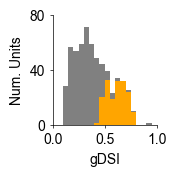

In [22]:
plt.figure(figsize=(4*cm,4*cm))
ax=plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.bar(bins[:-1]+bin_size/2,gdsi_hist,width=bin_size,color='gray')
plt.bar(bins[:-1]+bin_size/2,pass_gdsi_hist,width=bin_size,color='orange')

plt.xlim([0,1])
plt.ylabel('Num. Units',fontproperties=arial_font)
plt.xlabel('gDSI',fontproperties=arial_font)
plt.yticks([0,40,80],[0,40,80],fontproperties=arial_font)
plt.xticks([0,0.5,1],[0.0,0.5,1.0],fontproperties=arial_font)
plt.tight_layout(pad=0.05)
#plt.savefig(save_path+'gDSI_distribution.svg',format='svg',dpi=900)
plt.show()
#plt.close()

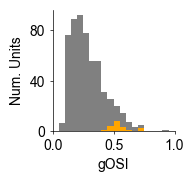

In [26]:
plt.figure(figsize=(4*cm,4*cm))
ax=plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.bar(bins[:-1]+bin_size/2,gosi_hist,width=bin_size,color='gray')
plt.bar(bins[:-1]+bin_size/2,pass_gosi_hist,width=bin_size,color='orange')

plt.xlim([0,1])
plt.ylabel('Num. Units',fontproperties=arial_font)
plt.xlabel('gOSI',fontproperties=arial_font)
plt.yticks([0,40,80],[0,40,80],fontproperties=arial_font)
plt.xticks([0,0.5,1],[0.0,0.5,1.0],fontproperties=arial_font)
#plt.savefig(save_path+'gOSI_distribution.svg',format='svg',dpi=900)
plt.show()
#plt.close()

In [11]:
DSI_Ps=np.load('/home/k/k-tsaridis/SQUID_EPHYS/VISION_PAPER_SUPP/DATASET_DSI_Ps.npy',allow_pickle=True)
OSI_Ps=np.load('/home/k/k-tsaridis/SQUID_EPHYS/VISION_PAPER_SUPP/DATASET_OSI_Ps.npy',allow_pickle=True)
DIRs=np.load('/home/k/k-tsaridis/SQUID_EPHYS/VISION_PAPER_SUPP/DATASET_DIRs.npy',allow_pickle=True)
ORIs=np.load('/home/k/k-tsaridis/SQUID_EPHYS/VISION_PAPER_SUPP/DATASET_ORIs.npy',allow_pickle=True)
GDSIs=np.load('/home/k/k-tsaridis/SQUID_EPHYS/VISION_PAPER_SUPP/DATASET_GDSIs.npy',allow_pickle=True)
GOSIs=np.load('/home/k/k-tsaridis/SQUID_EPHYS/VISION_PAPER_SUPP/DATASET_GOSIs.npy',allow_pickle=True)

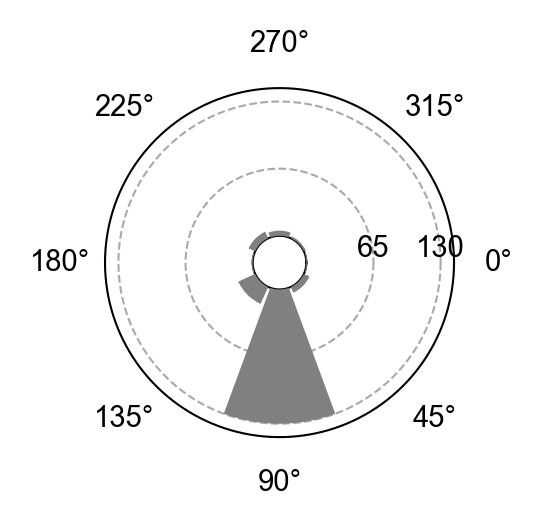

In [30]:
import numpy as np
import matplotlib.pyplot as plt

# Convert angles and counts
angles = np.deg2rad(np.asarray(set_ORI).astype(float))
counts = np.asarray(count_dirs)

# Wrap around for continuity
angles = np.append(angles, angles[0])
counts = np.append(counts, counts[0])

# Scaling
max_count = counts.max()
offset = max_count * 0.2
r_max = max_count                 # highest dashed ring at max bar height
outer_ring = max_count * 1.3     # black perimeter ring
step = r_max / 2                 # Now only two rings

# Figure setup
fig = plt.figure(figsize=(4/2.54, 4/2.54), dpi=300)
ax = plt.subplot(111, projection='polar')

# Plot bars
bar_width = np.deg2rad(360 / (len(counts) - 1)) * 0.9
bars = ax.bar(angles[:-1], counts[:-1], width=bar_width,
              bottom=offset, color='gray', align='center',
              zorder=10, linewidth=0)

# Angle space
theta = np.linspace(0, 2 * np.pi, 500)

# Draw offset ring
ax.plot(theta, [offset]*len(theta), color='black', linewidth=0.5)

# Draw 2 dashed rings
r_ticks = [offset + step, offset + 2*step]
for r in r_ticks:
    ax.plot(theta, [r]*len(theta), color='darkgray', linestyle='--', linewidth=0.5)
    ax.text(0, r, f"{int(r - offset)}", ha='center', va='bottom', fontsize=7, fontproperties=arial_font)

# Draw outer black perimeter ring
ax.plot(theta, [outer_ring]*len(theta), color='black', linewidth=0.5)

# Axis styling
ax.set_theta_zero_location('E')
ax.set_theta_direction(-1)
ax.set_xticks(np.deg2rad(np.asarray(set_ORI).astype(float)))
ax.set_xticklabels([f"{int(a)}°" for a in set_ORI], fontproperties=arial_font,fontsize=7)
ax.yaxis.grid(False)
ax.xaxis.grid(False)
ax.set_yticklabels([])
ax.tick_params(pad=0)
ax.spines['polar'].set_visible(False)

# Save
#plt.savefig(save_path + '/Dir_distribution_radial.svg', format='svg', dpi=600, bbox_inches='tight')
#plt.savefig(save_path + '/Dir_distribution_radial.pdf', format='pdf', dpi=600, bbox_inches='tight')

plt.show()
#plt.close()


